**import libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

In [2]:
data_path = Path('/Users/hangluahhatneizou/Downloads/archive')
orders = pd.read_csv(data_path/'olist_orders_dataset.csv')
items = pd.read_csv(data_path/'olist_order_items_dataset.csv')
products = pd.read_csv(data_path/'olist_products_dataset.csv')
order_payments = pd.read_csv(data_path/'olist_order_payments_dataset.csv')
order_reviews = pd.read_csv(data_path/'olist_order_reviews_dataset.csv')
sellers = pd.read_csv(data_path/'olist_sellers_dataset.csv')
product_category = pd.read_csv(data_path/'product_category_name_translation.csv')

**initial exploration**

In [3]:
orders = orders.copy()

**converting the date columns to datetime**

In [4]:
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

**helper column**

In [5]:
orders['purchase_year'] = orders['order_purchase_timestamp'].dt.year
orders['purchase_month'] = orders['order_purchase_timestamp'].dt.to_period('M')
orders['purchase_week'] = orders['order_purchase_timestamp'].dt.to_period('W')
orders['purchase_date'] = orders['order_purchase_timestamp'].dt.date

In [6]:
status_counts = orders['order_status'].value_counts()
status_pct = orders['order_status'].value_counts(normalize=True).mul(100).round(2)
status_summary = pd.DataFrame({
    'count': status_counts,
    'percentage': status_pct
})
print("\n === Order Status Distribution ===")
print(status_summary)


 === Order Status Distribution ===
              count  percentage
order_status                   
delivered     96478       97.02
shipped        1107        1.11
canceled        625        0.63
unavailable     609        0.61
invoiced        314        0.32
processing      301        0.30
created           5        0.01
approved          2        0.00


In [7]:
yearly_orders = orders.groupby('purchase_year').size().rename('order_count')
monthly_orders = orders.groupby('purchase_month').size().rename('order_count')
weekly_orders = orders.groupby('purchase_week').size().rename('order_count')
print(f"{yearly_orders}, {monthly_orders}, {weekly_orders}")


purchase_year
2016      329
2017    45101
2018    54011
Name: order_count, dtype: int64, purchase_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: order_count, dtype: int64, purchase_week
2016-08-29/2016-09-04      1
2016-09-05/2016-09-11      1
2016-09-12/2016-09-18      2
2016-09-26/2016-10-02      1
2016-10-03/2016-10-09    283
                        ... 
2018-09-10/2018-09-16      4
2018-09-17/2018-09-23      2
2018-09-24/2018-09-30      3
2018-10-01/2018-10-07      2
2018-10-15/2018-10-21      2
Freq: W-SUN, Name: order_count, Length: 101, dtype: int64


**Filtering by year**

In [8]:
#orders in 2018
orders_2018 = orders.query('purchase_year == 2018')
#orders_2018 = orders[orders['purchase_year == 2018]

In [9]:
#only delivered orders in 2017-18
delivered_1718 = orders[
    (orders['order_status'] == 'Delivered') &
    (orders['purchase_year'].isin([2017, 2018]))
]

In [10]:
#cancelled orders
cancelled = orders[orders['order_status'] == 'canceled']

**Visualizations**

In [11]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

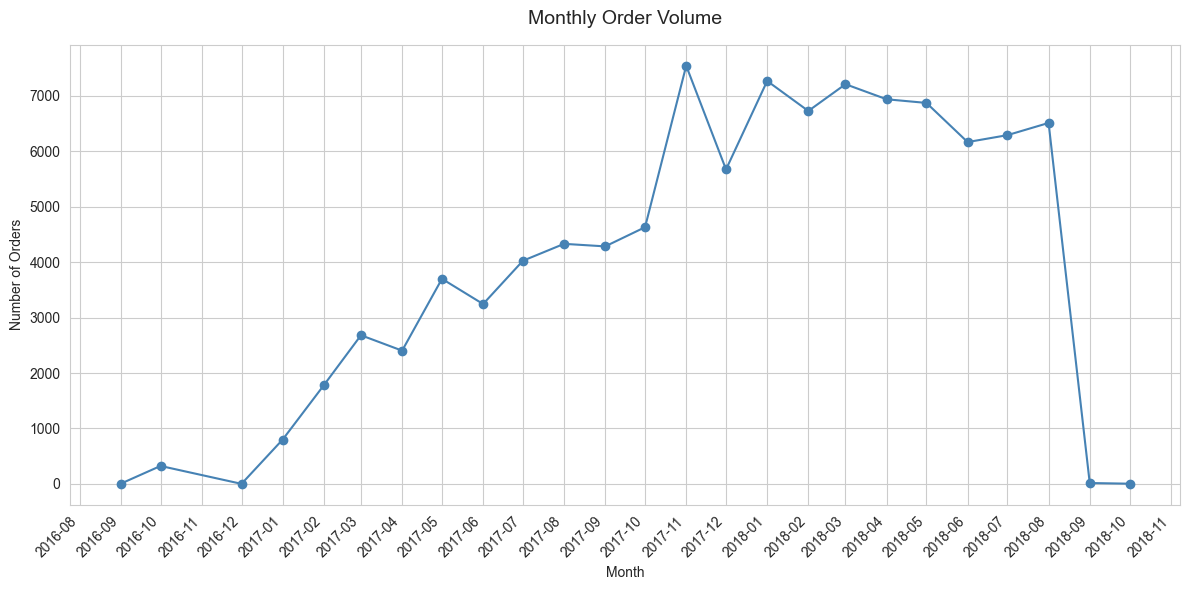

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(monthly_orders.index.to_timestamp(),
        monthly_orders.values, marker='o', color='steelblue',)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.title('Monthly Order Volume', fontsize=14, pad=15)
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

<>:3: SyntaxWarning: invalid escape sequence '\~'
<>:3: SyntaxWarning: invalid escape sequence '\~'
/var/folders/j6/lkx91m6j7hx3m_yhv2mzyc4c0000gn/T/ipykernel_87014/2222432374.py:3: SyntaxWarning: invalid escape sequence '\~'
  plt.title('Weekly Order Volume (Last \~6 months)', fontsize=14, pad=15)


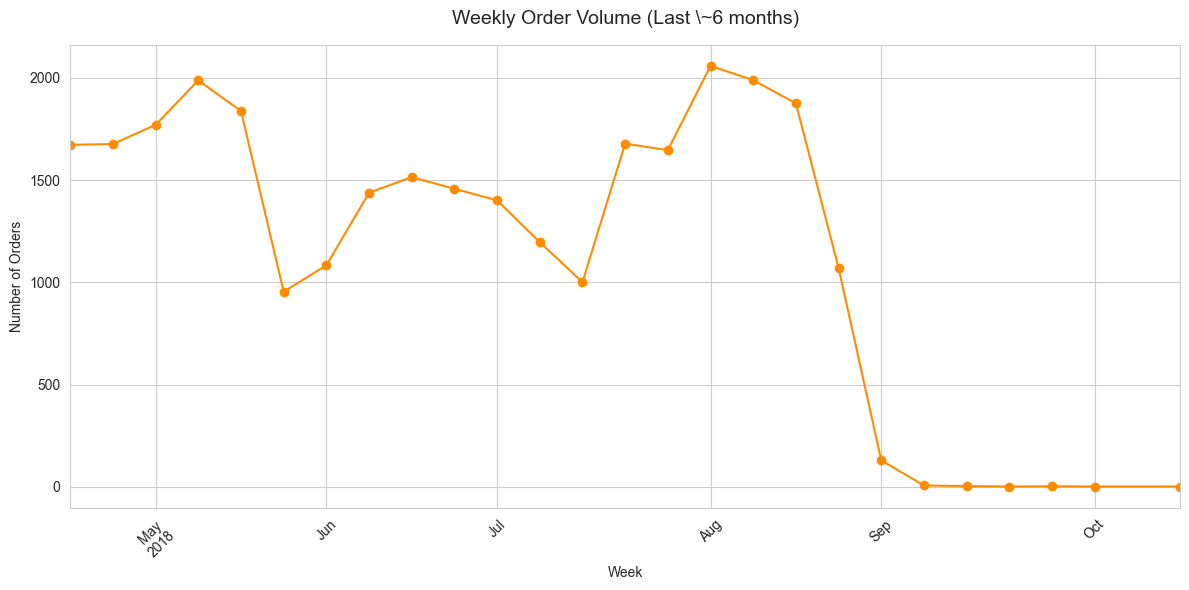

In [13]:
plt.figure()
weekly_orders.tail(26).plot(kind='line', marker='o', color='darkorange')
plt.title('Weekly Order Volume (Last \~6 months)', fontsize=14, pad=15)
plt.xlabel('Week')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

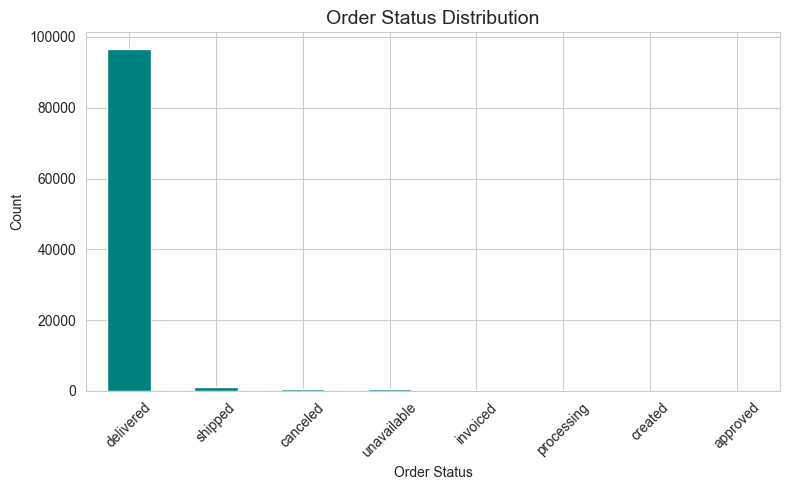

In [14]:
plt.figure(figsize=(8, 5))
status_summary['count'].plot(kind='bar', color='teal')
plt.title('Order Status Distribution', fontsize=14)
plt.xlabel('Order Status')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

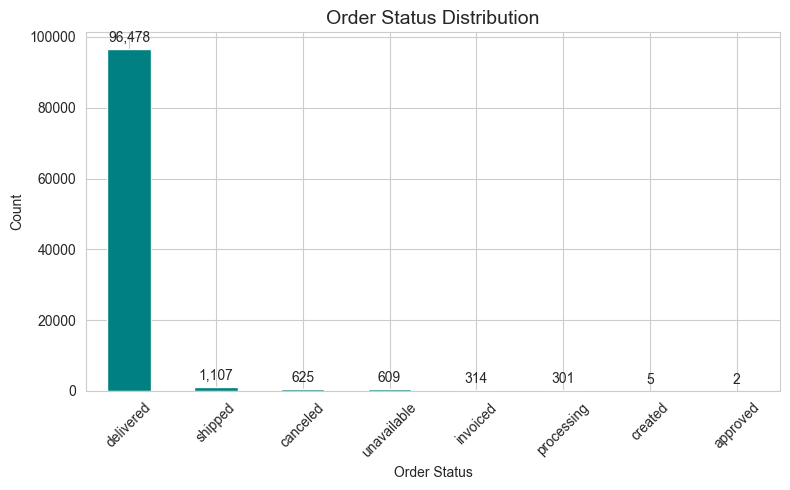

In [17]:
plt.figure(figsize=(8, 5))
ax = status_summary["count"].plot(kind='bar', color='teal')
plt.title('Order Status Distribution', fontsize=14)
plt.xlabel('Order Status')
plt.ylabel('Count')
plt.xticks(rotation=45)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{int(height):,}",
        (p.get_x() + p.get_width()/ 2.0, height,
         ),
        ha='center',
        va='bottom',
        xytext=(0, 3),
        textcoords='offset points',
        fontsize=10,
    )
plt.tight_layout()
plt.show()